# InSAR outcome label, spatial split and class boundaries

Run the cells **from top to bottom** (Shift+Enter). Keep this notebook in the repo folder, next to `build_dataset.py`, with `data/insar_points.zip` already downloaded.

| Step | What it does | Time |
|---|---|---|
| 1 | Reads every CSV in DWR's zip and keeps only the points inside the study area, saved to `data/insar_study_area.csv` | slow (probably 10-30 min), runs once |
| 2 | Prints what is in that file: dates, how many points have readings, units/sign checks | about a minute |
| 3 | Builds the label, the spatial-block train/test split and the class boundaries (training cells only) | about a minute, **stays switched off until you confirm units and sign** |
| 4 | Draws the label map, split map and distribution from the real output | seconds |

**How the label is measured.** Most points do not have a reading on every date, so the label does not rely on two exact dates. For each InSAR point, a straight line is fitted through all its valid readings inside the outcome window; the line's slope times the window length is that point's displacement over the window. A cell's label is the median of the usable points inside it (the median, so a few odd points inside one cell cannot swing it).

In [22]:
# ---- Settings (edit here, nothing else) ----
from pathlib import Path

DATA        = Path("data")
GRID_CSV    = DATA / "subsidence_dataset.csv"
INSAR_SRC   = DATA / "insar_points.zip"        # the zip, or a folder of CSVs extracted with 7-Zip
STUDY_CSV   = DATA / "insar_study_area.csv"    # written by Step 1
EXTRACT_LOG = DATA / "insar_extract_log.json"  # written by Step 1
OUT_CSV     = DATA / "subsidence_dataset_processed.csv"
LOG_JSON    = DATA / "label_build_log.json"
FIG_DIR     = Path("figures")

START, END = "2020-01-01", "2024-12-31"   # outcome window (1.4 in the document)
CRS        = "EPSG:4326"                  # CRS of the InSAR lat/lon columns
POSITIVE_IS_SINKING = False               # False: negative values in the file mean sinking
MIN_OBS       = 20                        # a point needs at least this many valid readings inside the window
MIN_SPAN_FRAC = 0.6                       # ...and they must cover at least this share of the window's length
CELL_M, BLOCK_M, TEST_FRAC, SEED = 500.0, 5000.0, 0.25, 42

REDO_EXTRACT = False                      # True forces Step 1 to run again
CONFIRMED_UNITS_AND_SIGN = True          # set True only after Step 2 and the DWR report agree

In [23]:
# ---- Helpers (just run) ----
import hashlib, json, platform, re, time, warnings, zipfile
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pyproj import Transformer
from scipy.spatial import cKDTree

LABELS    = ["very_low", "low", "moderate", "high", "very_high"]
LAT_NAMES = ["latitude", "lat", "point_y", "y"]
LON_NAMES = ["longitude", "lon", "long", "lng", "point_x", "x"]
READ      = dict(low_memory=False, encoding_errors="replace")


def find_col(cols, names, kind):
    lower = {str(c).lower(): c for c in cols}
    for n in names:
        if n in lower:
            return lower[n]
    raise RuntimeError(f"Could not find a {kind} column. Columns start with {list(cols)[:25]}. "
                       f"Add the right name to {kind.upper()}_NAMES in this cell.")


def date_value(name):
    s = str(name).strip()
    digits = re.sub(r"\D", "", s)
    if len(digits) == 8:
        d = pd.to_datetime(digits, format="%Y%m%d", errors="coerce")
        if pd.notna(d) and 2010 <= d.year <= 2035:
            return d
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        d = pd.to_datetime(s.lstrip("Dd_"), errors="coerce")
    if pd.notna(d) and 2010 <= d.year <= 2035 and not s.isdigit():
        return d
    return pd.NaT


def date_columns(cols):
    return sorted((date_value(c), c) for c in cols if pd.notna(date_value(c)))


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 22), b""):
            h.update(chunk)
    return h.hexdigest()


class Source:
    def __init__(self, path):
        p = Path(path)
        if not p.exists():
            raise RuntimeError(f"{path} does not exist.")
        self.zf = None
        if p.is_dir():
            self.members = sorted(p.rglob("*.csv"))
            self.names = [str(m.relative_to(p)) for m in self.members]
        elif p.suffix.lower() == ".zip":
            self.zf = zipfile.ZipFile(p)
            self.members = sorted((i for i in self.zf.infolist() if i.filename.lower().endswith(".csv")),
                                  key=lambda i: i.filename)
            self.names = [i.filename for i in self.members]
        else:
            self.members, self.names = [p], [p.name]
        if not self.members:
            raise RuntimeError(f"No .csv files found in {path}.")

    def open(self, i):
        m = self.members[i]
        try:
            return self.zf.open(m) if self.zf else open(m, "rb")
        except NotImplementedError as e:
            raise RuntimeError(
                f"Python cannot read this zip's compression method ({e}). Extract the zip with 7-Zip "
                f"(right-click > 7-Zip > Extract to ...) into a folder inside data\\, then set INSAR_SRC in "
                f"the Settings cell to that folder.")


def window_columns():
    cols = list(pd.read_csv(STUDY_CSV, nrows=0).columns)
    t0, t1 = pd.Timestamp(START), pd.Timestamp(END)
    win = [(d, c) for d, c in date_columns(cols) if t0 <= d <= t1]
    if len(win) < MIN_OBS:
        raise RuntimeError(f"Only {len(win)} date columns fall inside {START} to {END} (MIN_OBS is {MIN_OBS}). "
                           f"If Step 1 kept too few, check START/END and set REDO_EXTRACT = True.")
    return cols, win


def window_trends(chunksize=50_000):
    # One row per InSAR point: straight-line fit of value against time over all valid readings in the window.
    cols, win = window_columns()
    lat_c, lon_c = find_col(cols, LAT_NAMES, "lat"), find_col(cols, LON_NAMES, "lon")
    wcols = [c for _, c in win]
    t = np.array([(d - pd.Timestamp(START)).days / 365.25 for d, _ in win])
    win_years = (pd.Timestamp(END) - pd.Timestamp(START)).days / 365.25
    parts, avail, n_total = [], np.zeros(len(wcols)), 0
    for ch in pd.read_csv(STUDY_CSV, usecols=[lat_c, lon_c] + wcols, chunksize=chunksize, low_memory=False):
        V = ch[wcols].apply(pd.to_numeric, errors="coerce").to_numpy(dtype=float)
        M = np.isfinite(V)
        n = M.sum(1)
        T = np.broadcast_to(t, V.shape)
        with np.errstate(invalid="ignore", divide="ignore"):
            tbar = np.where(M, T, 0.0).sum(1) / n
            vbar = np.where(M, V, 0.0).sum(1) / n
            dt = np.where(M, T - tbar[:, None], 0.0)
            dv = np.where(M, V - vbar[:, None], 0.0)
            sxx, sxy, syy = (dt ** 2).sum(1), (dt * dv).sum(1), (dv ** 2).sum(1)
            slope = sxy / sxx
            r2 = sxy ** 2 / (sxx * syy)
            span = np.where(M, T, -np.inf).max(1) - np.where(M, T, np.inf).min(1)
        span = np.where(n >= 2, span, 0.0)
        lon = pd.to_numeric(ch[lon_c], errors="coerce").to_numpy()
        lat = pd.to_numeric(ch[lat_c], errors="coerce").to_numpy()
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")          # rows with no readings at all give an all-NaN warning
            maxabs = np.nanmax(np.abs(np.where(M, V, np.nan)), axis=1)
        parts.append(pd.DataFrame({"lon": lon, "lat": lat, "n_obs": n, "span_yr": span, "slope_per_yr": slope,
                                   "r2": r2, "maxabs": maxabs}))
        avail += M.sum(0)
        n_total += len(ch)
    pts = pd.concat(parts, ignore_index=True)
    pts["ok"] = (pts.n_obs >= MIN_OBS) & (pts.span_yr >= MIN_SPAN_FRAC * win_years) & np.isfinite(pts.slope_per_yr)
    pts["window_total"] = pts.slope_per_yr * win_years        # displacement over the window, file sign and units
    return pts, pd.Series(avail / n_total, index=[d for d, _ in win]), win_years


print("helpers ready; pandas", pd.__version__)

helpers ready; pandas 3.0.5


## Step 1 - keep only the study-area points (slow, runs once)
For every CSV in the zip it first reads just the latitude/longitude columns to see whether that file reaches the study area, and only reads the full rows of files that do. It also keeps the first date column in each file and the date columns within about six months of the outcome window.

In [24]:
def extract_study_area(pad_days=180, chunk=100_000):
    if STUDY_CSV.exists() and not REDO_EXTRACT:
        print(f"{STUDY_CSV} already exists ({STUDY_CSV.stat().st_size / 1e6:.0f} MB), so Step 1 is skipped. "
              f"Set REDO_EXTRACT = True in Settings to run it again.")
        return
    grid = pd.read_csv(GRID_CSV, usecols=["longitude", "latitude"])
    m = 0.01
    xmin, xmax = grid.longitude.min() - m, grid.longitude.max() + m
    ymin, ymax = grid.latitude.min() - m, grid.latitude.max() + m
    print(f"Study-area box: lon {xmin:.4f} to {xmax:.4f}, lat {ymin:.4f} to {ymax:.4f}")
    to_ll = None if CRS.upper() == "EPSG:4326" else Transformer.from_crs(CRS, "EPSG:4326", always_xy=True)

    def lonlat(df, lon_c, lat_c):
        lon = pd.to_numeric(df[lon_c], errors="coerce").to_numpy()
        lat = pd.to_numeric(df[lat_c], errors="coerce").to_numpy()
        return to_ll.transform(lon, lat) if to_ll is not None else (lon, lat)

    src = Source(INSAR_SRC)
    print(f"{len(src.members)} CSV file(s) found in {INSAR_SRC}\n")
    kept, log_files, t_all = [], [], time.time()
    lo_d = pd.Timestamp(START) - pd.Timedelta(days=pad_days)
    hi_d = pd.Timestamp(END) + pd.Timedelta(days=pad_days)

    for i, name in enumerate(src.names):
        t0 = time.time()
        with src.open(i) as fh:
            cols = list(pd.read_csv(fh, nrows=0, **READ).columns)
        lat_c, lon_c = find_col(cols, LAT_NAMES, "lat"), find_col(cols, LON_NAMES, "lon")
        dates = date_columns(cols)
        if not dates:
            raise RuntimeError(f"{name}: no date-like column names. Columns start with {cols[:25]}")
        keep_dates = [dates[0][1]] + [c for d, c in dates if lo_d <= d <= hi_d and c != dates[0][1]]
        if len(keep_dates) < 3:
            raise RuntimeError(f"{name}: date columns run {dates[0][0].date()} to {dates[-1][0].date()}, which "
                               f"does not reach the window {START} to {END}. Change START/END in Settings.")
        date_names = {c for _, c in dates}
        keep_cols = [c for c in cols if c not in date_names] + keep_dates

        # pass 1: coordinates only
        hit, n_rows, span = [], 0, [np.inf, -np.inf, np.inf, -np.inf]
        with src.open(i) as fh:
            for ch in pd.read_csv(fh, usecols=[lon_c, lat_c], chunksize=500_000, **READ):
                lon, lat = lonlat(ch, lon_c, lat_c)
                if np.isfinite(lat).any():
                    span = [min(span[0], np.nanmin(lat)), max(span[1], np.nanmax(lat)),
                            min(span[2], np.nanmin(lon)), max(span[3], np.nanmax(lon))]
                inside = (lon >= xmin) & (lon <= xmax) & (lat >= ymin) & (lat <= ymax)
                hit.append(np.flatnonzero(inside) + n_rows)
                n_rows += len(ch)
                if (n_rows // 500_000) % 4 == 0:
                    print(f"      {name}: {n_rows:,} rows scanned...", end="\r")
        hit = np.concatenate(hit) if hit else np.array([], dtype=int)
        print(f"[{i + 1}/{len(src.names)}] {name}: {n_rows:,} points, {len(hit):,} in the study area "
              f"(covers lat {span[0]:.2f}..{span[1]:.2f}, lon {span[2]:.2f}..{span[3]:.2f}; "
              f"{len(dates)} dates {dates[0][0].date()} to {dates[-1][0].date()}); {time.time() - t0:.0f} s" + " " * 20)

        # pass 2: full rows, only for files that reach the study area
        if len(hit):
            base = 0
            with src.open(i) as fh:
                for ch in pd.read_csv(fh, usecols=keep_cols, chunksize=chunk, **READ):
                    sel = np.isin(np.arange(base, base + len(ch)), hit)
                    if sel.any():
                        kept.append(ch.loc[sel].assign(source_file=name))
                    base += len(ch)
        log_files.append({"file": name, "points": int(n_rows), "in_study_area": int(len(hit)),
                          "lat_range": [float(span[0]), float(span[1])], "lon_range": [float(span[2]), float(span[3])],
                          "date_columns_in_file": len(dates),
                          "date_range": [str(dates[0][0].date()), str(dates[-1][0].date())]})

    if not kept:
        raise RuntimeError("No points fell inside the study-area box in any file. Check CRS and the lat/lon "
                           "columns (the line printed for each file shows what area it covers).")
    out = pd.concat(kept, ignore_index=True)
    lat_c, lon_c = find_col(out.columns, LAT_NAMES, "lat"), find_col(out.columns, LON_NAMES, "lon")
    n_before = len(out)
    out = out.drop_duplicates(subset=[lat_c, lon_c]).reset_index(drop=True)
    print(f"\n{n_before:,} points kept; {n_before - len(out):,} repeated coordinates (same point in more than one "
          f"file) removed -> {len(out):,} points.")
    DATA.mkdir(exist_ok=True)
    out.to_csv(STUDY_CSV, index=False)
    kept_dates = date_columns(out.columns)
    print(f"Saved {STUDY_CSV} ({STUDY_CSV.stat().st_size / 1e6:.0f} MB): {len(kept_dates)} date columns "
          f"({kept_dates[0][1]} ... {kept_dates[-1][1]}). Total time {(time.time() - t_all) / 60:.1f} min.")
    src_path = Path(INSAR_SRC)
    log = {"run_at": datetime.now().isoformat(timespec="seconds"), "src": str(INSAR_SRC),
           "src_bytes": src_path.stat().st_size if src_path.is_file() else None, "src_sha256": None,
           "bbox_lonlat": [xmin, ymin, xmax, ymax], "files": log_files,
           "points_kept": int(n_before), "points_after_dedup": int(len(out)), "output": str(STUDY_CSV)}
    if src_path.is_file():
        print("Hashing the source zip for the lineage record (about a minute)...")
        log["src_sha256"] = sha256(INSAR_SRC)
    EXTRACT_LOG.write_text(json.dumps(log, indent=2))
    print(f"Wrote {EXTRACT_LOG}")


extract_study_area()

data\insar_study_area.csv already exists (159 MB), so Step 1 is skipped. Set REDO_EXTRACT = True in Settings to run it again.


## Step 2 - look at what came out
Nothing is written here. It shows how many points have readings, how the straight-line fit behaves, and whether the numbers agree with DWR's own velocity column. Then check units, sign and "cumulative" in the DWR InSAR Data Report.

Per-file coverage (from Step 1):
  CALIFORNIA_DWR_10_VERT.csv: 217,035 points, 0 in the study area, dates 2015-01-01 to 2026-04-01
  CALIFORNIA_DWR_11_VERT.csv: 217,035 points, 0 in the study area, dates 2015-01-01 to 2026-04-01
  CALIFORNIA_DWR_12_VERT.csv: 217,035 points, 0 in the study area, dates 2015-01-01 to 2026-04-01
  CALIFORNIA_DWR_13_VERT.csv: 217,035 points, 0 in the study area, dates 2015-01-01 to 2026-04-01
  CALIFORNIA_DWR_14_VERT.csv: 217,035 points, 0 in the study area, dates 2015-01-01 to 2026-04-01
  CALIFORNIA_DWR_15_VERT.csv: 217,035 points, 0 in the study area, dates 2015-01-01 to 2026-04-01
  CALIFORNIA_DWR_16_VERT.csv: 217,035 points, 0 in the study area, dates 2015-01-01 to 2026-04-01
  CALIFORNIA_DWR_17_VERT.csv: 217,035 points, 0 in the study area, dates 2015-01-01 to 2026-04-01
  CALIFORNIA_DWR_18_VERT.csv: 217,035 points, 47,739 in the study area, dates 2015-01-01 to 2026-04-01
  CALIFORNIA_DWR_19_VERT.csv: 217,035 points, 54,104 in the study area, dates 20

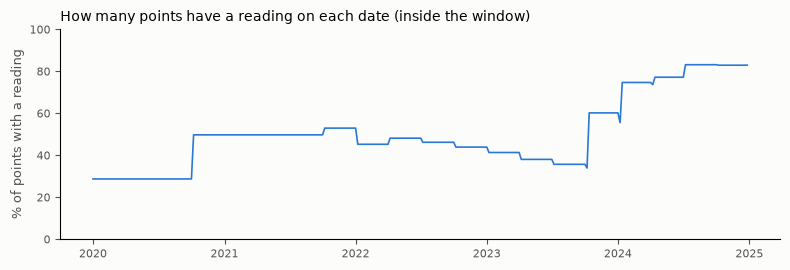

This cell only reads. Confirm units, sign and cumulative in the DWR report before Step 3.


In [25]:
import matplotlib.pyplot as plt


def inspect_study_area():
    cols = list(pd.read_csv(STUDY_CSV, nrows=0).columns)
    dates = date_columns(cols)
    date_names = {c for _, c in dates}
    other = [c for c in cols if c not in date_names]

    if EXTRACT_LOG.exists():
        print("Per-file coverage (from Step 1):")
        for f in json.loads(EXTRACT_LOG.read_text())["files"]:
            print(f"  {f['file'].split('/')[-1]}: {f['points']:,} points, {f['in_study_area']:,} in the study area, "
                  f"dates {f['date_range'][0]} to {f['date_range'][1]}")
    print("\nNon-date columns:", other)
    print(f"{len(dates)} date columns kept: {dates[0][1]} ({dates[0][0].date()}) ... {dates[-1][1]} ({dates[-1][0].date()})")
    first = pd.to_numeric(pd.read_csv(STUDY_CSV, usecols=[dates[0][1]], low_memory=False)[dates[0][1]], errors="coerce")
    print(f"The file's first date column {dates[0][1]} is {first.isna().mean():.1%} empty.")

    pts, avail, win_years = window_trends()
    n = len(pts)
    print(f"\n{n:,} points in the study area. Window {START} to {END} ({win_years:.2f} years), "
          f"{len(avail)} date columns inside it.")
    gaps = np.diff([d for d in avail.index]) / np.timedelta64(1, "D")
    print(f"Spacing between date columns: median {np.median(gaps):.0f} days (min {gaps.min():.0f}, max {gaps.max():.0f}).")
    print(f"Share of points with a reading on a given date: min {avail.min():.0%}, median {avail.median():.0%}, max {avail.max():.0%}.")
    print(f"Valid readings per point inside the window: 10th pct {pts.n_obs.quantile(.1):.0f}, "
          f"median {pts.n_obs.median():.0f}, 90th pct {pts.n_obs.quantile(.9):.0f}; {(pts.n_obs == 0).mean():.1%} have none.")
    print(f"Points usable for the label (at least {MIN_OBS} readings covering at least {MIN_SPAN_FRAC:.0%} of the window): "
          f"{pts.ok.sum():,} of {n:,} ({pts.ok.mean():.1%}).")

    good = pts[pts.ok]
    print(f"\nAmong usable points (file units, per year): slope median {good.slope_per_yr.median():.4g}, "
          f"10th pct {good.slope_per_yr.quantile(.1):.4g}, 90th pct {good.slope_per_yr.quantile(.9):.4g}; "
          f"share with a negative slope {(good.slope_per_yr < 0).mean():.1%}.")
    print(f"Straight-line fit quality: median R^2 {good.r2.median():.2f}. A high value means the readings drift "
          f"steadily with time, as accumulated displacement does.")
    print(f"Largest absolute reading in the window: {pts.maxabs.max():.5g}. If the file is in millimetres that is "
          f"{pts.maxabs.max() / 304.8:.1f} ft; if it were already in feet it would be impossible, so check the report.")

    for c in other:
        if re.search(r"vel|rate", str(c), re.I):
            v = pd.to_numeric(pd.read_csv(STUDY_CSV, usecols=[c], low_memory=False)[c], errors="coerce")
            both = pd.DataFrame({"vel": v.to_numpy(), "slope": pts.slope_per_yr.to_numpy(), "ok": pts.ok.to_numpy()})
            both = both[both.ok & both.vel.notna()]
            ratio = (both.slope / both.vel.where(both.vel.abs() > 1e-9)).median()
            print(f"\nCross-check with {c!r} (DWR's own velocity column): median {c} = {v.median():.4g}; "
                  f"correlation with my window slope {both.slope.corr(both.vel):.2f}; median slope/{c} = {ratio:.2f}; "
                  f"same sign for {(np.sign(both.slope) == np.sign(both.vel)).mean():.1%} of points.")
            print("  Ratio near 1 means the displacement columns and the velocity column use the same length unit "
                  "per year; the window can differ from the full-record velocity, so only a rough match is expected.")

    fig, ax = plt.subplots(figsize=(8, 2.8), facecolor="#fcfcfb")
    ax.set_facecolor("#fcfcfb")
    ax.plot(avail.index, avail.values * 100, color="#2a78d6", lw=1.2)
    ax.set_ylim(0, 100)
    ax.set_ylabel("% of points with a reading", fontsize=9, color="#52514e")
    ax.set_title("How many points have a reading on each date (inside the window)", loc="left", fontsize=10)
    ax.tick_params(labelsize=8, colors="#52514e")
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    fig.tight_layout()
    plt.show()
    print("This cell only reads. Confirm units, sign and cumulative in the DWR report before Step 3.")


inspect_study_area()

## Step 2b - does the window slope make sense?
Reads only. Compares each point's window slope with DWR's own velocity column, maps both, and shows the raw readings of ten random points.

VEL_V: median -107.8, 10th pct -183.2, 90th pct -48.6; negative for 99.5% of all points
My window slope (usable points): median -67.7, 10th pct -176.7, 90th pct 56.5
Correlation of window slope with VEL_V: Pearson 0.04, Spearman 0.15, Pearson without the most extreme 1% 0.07
Usable points with slope below -50 per year: 54.6%; above +50: 10.2%; extreme (beyond +-1000): 0


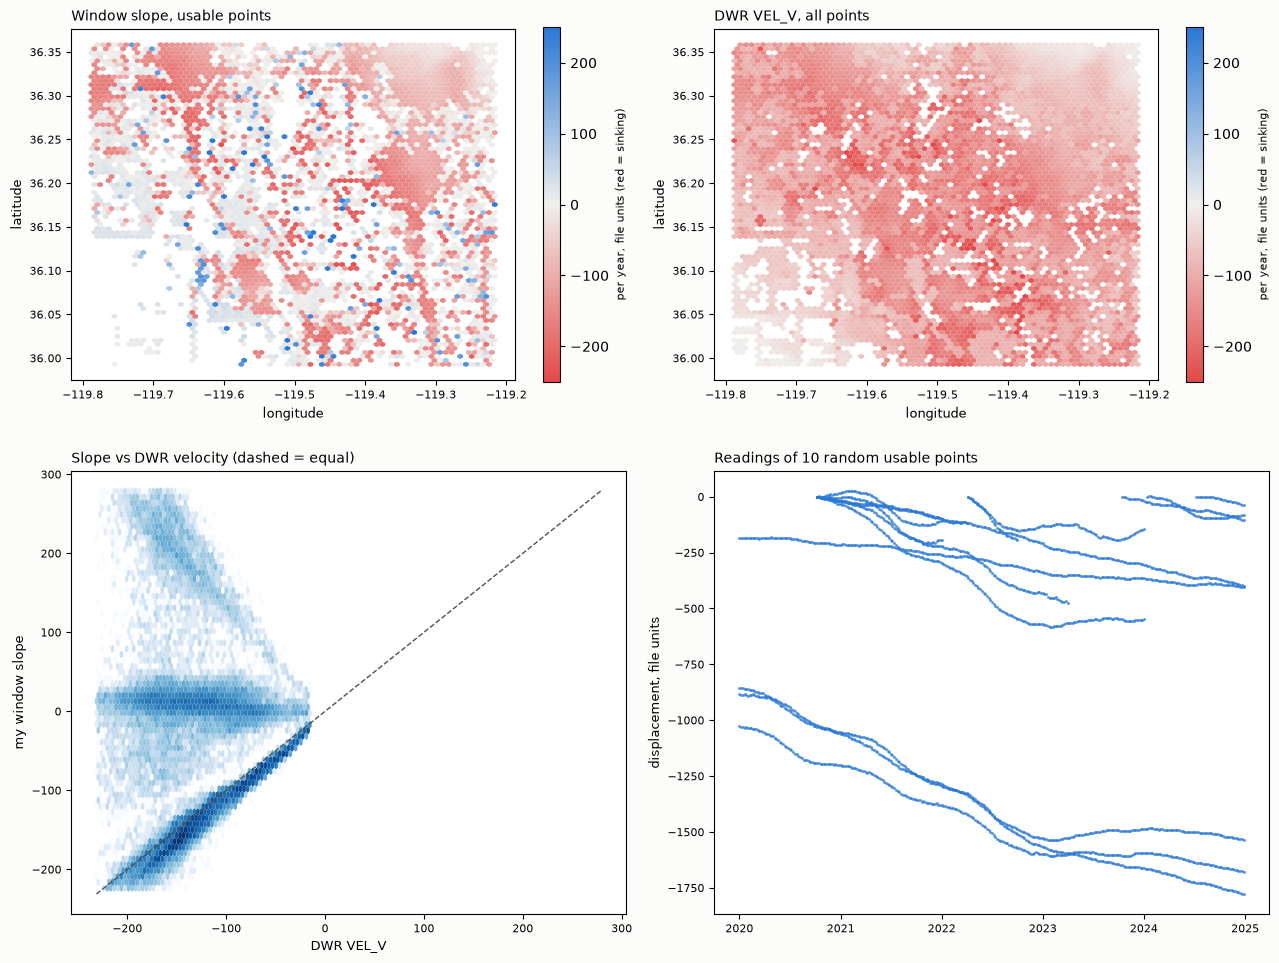

In [26]:
# ---- Step 2b: does the window slope make sense? (reads only, writes nothing) ----
from matplotlib.colors import LinearSegmentedColormap

VEL_COL = "VEL_V"
pts, avail, win_years = window_trends()
pts["vel"] = pd.to_numeric(pd.read_csv(STUDY_CSV, usecols=[VEL_COL], low_memory=False)[VEL_COL], errors="coerce").to_numpy()
good = pts[pts.ok & pts.vel.notna()].copy()

print(f"{VEL_COL}: median {pts.vel.median():.1f}, 10th pct {pts.vel.quantile(.1):.1f}, 90th pct {pts.vel.quantile(.9):.1f}; "
      f"negative for {(pts.vel < 0).mean():.1%} of all points")
print(f"My window slope (usable points): median {good.slope_per_yr.median():.1f}, 10th pct {good.slope_per_yr.quantile(.1):.1f}, "
      f"90th pct {good.slope_per_yr.quantile(.9):.1f}")
s_lo, s_hi = good.slope_per_yr.quantile([.01, .99])
v_lo, v_hi = good.vel.quantile([.01, .99])
trim = good[good.slope_per_yr.between(s_lo, s_hi) & good.vel.between(v_lo, v_hi)]
print(f"Correlation of window slope with {VEL_COL}: Pearson {good.slope_per_yr.corr(good.vel):.2f}, "
      f"Spearman {good.slope_per_yr.corr(good.vel, method='spearman'):.2f}, "
      f"Pearson without the most extreme 1% {trim.slope_per_yr.corr(trim.vel):.2f}")
print(f"Usable points with slope below -50 per year: {(good.slope_per_yr < -50).mean():.1%}; "
      f"above +50: {(good.slope_per_yr > 50).mean():.1%}; extreme (beyond +-1000): {(good.slope_per_yr.abs() > 1000).sum():,}")

cmap = LinearSegmentedColormap.from_list("sink", ["#e34948", "#f0efec", "#2a78d6"])   # red = sinking, blue = rising
lim = 250
asp = 1 / np.cos(np.deg2rad(pts.lat.mean()))
fig, axes = plt.subplots(2, 2, figsize=(13, 10), facecolor="#fcfcfb")
for ax, col, data, title in [(axes[0, 0], "slope_per_yr", good, "Window slope, usable points"),
                             (axes[0, 1], "vel", pts[pts.vel.notna()], f"DWR {VEL_COL}, all points")]:
    hb = ax.hexbin(data.lon, data.lat, C=data[col], reduce_C_function=np.median, gridsize=70, cmap=cmap,
                   vmin=-lim, vmax=lim, mincnt=3, linewidths=0)
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_aspect(asp)
    ax.set_xlabel("longitude", fontsize=9); ax.set_ylabel("latitude", fontsize=9)
    fig.colorbar(hb, ax=ax, shrink=0.8).set_label("per year, file units (red = sinking)", fontsize=8)

ax = axes[1, 0]
ax.hexbin(trim.vel, trim.slope_per_yr, gridsize=60, cmap="Blues", mincnt=1, bins="log", linewidths=0)
lo_, hi_ = min(trim.vel.min(), trim.slope_per_yr.min()), max(trim.vel.max(), trim.slope_per_yr.max())
ax.plot([lo_, hi_], [lo_, hi_], color="#52514e", lw=1, ls="--")
ax.set_xlabel(f"DWR {VEL_COL}", fontsize=9); ax.set_ylabel("my window slope", fontsize=9)
ax.set_title("Slope vs DWR velocity (dashed = equal)", loc="left", fontsize=10)

cols, win = window_columns()
wcols, wdates = [c for _, c in win], [d for d, _ in win]
pick = set(np.random.default_rng(0).choice(np.flatnonzero(pts.ok.to_numpy()), 10, replace=False).tolist())
rows, base = {}, 0
for ch in pd.read_csv(STUDY_CSV, usecols=wcols, chunksize=50_000, low_memory=False):
    for p in pick:
        if base <= p < base + len(ch):
            rows[p] = pd.to_numeric(ch.iloc[p - base], errors="coerce").to_numpy(dtype=float)
    base += len(ch)
ax = axes[1, 1]
for y in rows.values():
    ax.plot(wdates, y, ".", ms=2.5, color="#2a78d6", alpha=0.6)
ax.set_title("Readings of 10 random usable points", loc="left", fontsize=10)
ax.set_ylabel("displacement, file units", fontsize=9)
for a in axes.ravel():
    a.tick_params(labelsize=8)
fig.tight_layout()
plt.show()

## Step 3 - label, split and class boundaries
Switched off until `CONFIRMED_UNITS_AND_SIGN = True` in the Settings cell. It also adds the `soil_missing` flag (no imputation, nothing dropped).

* The label is the displacement over the window (straight-line fit through each point's valid readings, slope times window length), taken as the median over the usable InSAR points inside each 500 m cell, with positive meaning sinking.
* The train/test split assigns whole 5 km blocks (not single cells) to train or test, with seed 42.
* The five class boundaries (20th, 40th, 60th, 80th percentile) are computed from training cells only.
* Cells with no usable InSAR point get no label and are left out of training and evaluation.

In [27]:
def build_label():
    if not CONFIRMED_UNITS_AND_SIGN:
        print("Step 3 not run. Set CONFIRMED_UNITS_AND_SIGN = True in the Settings cell once Step 2 and the DWR "
              "report agree on units and sign (and set POSITIVE_IS_SINKING if the file says positive = sinking).")
        return None
    df = pd.read_csv(GRID_CSV)
    for c in ["grid_id", "longitude", "latitude", "clay_pct"]:
        if c not in df.columns:
            raise RuntimeError(f"{GRID_CSV} has no column {c!r}")
    log = {"run_at": datetime.now().isoformat(timespec="seconds"), "python": platform.python_version(),
           "pandas": pd.__version__,
           "settings": {"START": START, "END": END, "CRS": CRS, "POSITIVE_IS_SINKING": POSITIVE_IS_SINKING,
                        "MIN_OBS": MIN_OBS, "MIN_SPAN_FRAC": MIN_SPAN_FRAC,
                        "CELL_M": CELL_M, "BLOCK_M": BLOCK_M, "TEST_FRAC": TEST_FRAC, "SEED": SEED},
           "label_method": "per-point least-squares slope over all valid readings in the window, times window length; "
                           "cell label = median over the usable points inside the cell",
           "input_csv": {"path": str(GRID_CSV), "sha256": sha256(GRID_CSV), "rows": len(df), "cols": df.shape[1]}}

    # soil flag (flag only: no imputation, no dropping)
    df["soil_missing"] = df["clay_pct"].isna().astype(int)
    print(f"soil_missing = 1 for {df.soil_missing.sum()} of {len(df)} cells ({df.soil_missing.mean():.1%}); "
          f"no values imputed or dropped.")
    log["soil_missing_cells"] = int(df.soil_missing.sum())

    # per-point displacement over the window
    pts, avail, win_years = window_trends()
    ok = pts[pts.ok].copy()
    print(f"\n{len(pts):,} study-area points; {len(ok):,} ({len(ok) / len(pts):.1%}) have at least {MIN_OBS} valid "
          f"readings covering at least {MIN_SPAN_FRAC:.0%} of {START} to {END}.")
    lon, lat = ok.lon.to_numpy(), ok.lat.to_numpy()
    if CRS.upper() != "EPSG:4326":
        lon, lat = Transformer.from_crs(CRS, "EPSG:4326", always_xy=True).transform(lon, lat)
    sign = 1 if POSITIVE_IS_SINKING else -1
    rising = (sign * ok.slope_per_yr) < -50
    print(f"Usable points that rise by more than 50 per year over the window (opposite to sinking): {rising.sum():,} "
          f"({rising.mean():.1%}). They stay in the label; the median per cell limits their effect.")
    ok["subsidence"] = sign * ok.window_total            # positive = sinking, file units, over the window

    # points -> 500 m cells (square cells in EPSG:5070)
    to5070 = Transformer.from_crs("EPSG:4326", "EPSG:5070", always_xy=True)
    cx, cy = to5070.transform(df.longitude.to_numpy(), df.latitude.to_numpy())
    px, py = to5070.transform(lon, lat)
    tree = cKDTree(np.c_[cx, cy])
    dist, idx = tree.query(np.c_[px, py], k=1, p=np.inf, distance_upper_bound=CELL_M / 2)
    inside = idx < len(df)
    g = (pd.DataFrame({"idx": idx[inside], "s": ok["subsidence"].to_numpy()[inside]})
         .groupby("idx")["s"].agg(["median", "size"]))
    df["insar_disp_window"] = np.nan
    df["subsidence"] = np.nan
    df["insar_n_points"] = 0
    df.loc[g.index, "subsidence"] = g["median"].to_numpy()
    df.loc[g.index, "insar_disp_window"] = g["median"].to_numpy() * sign
    df.loc[g.index, "insar_n_points"] = g["size"].to_numpy()
    labeled = df["subsidence"].notna()
    print(f"{inside.sum():,} usable InSAR points fell inside grid cells; {labeled.sum():,} of {len(df):,} cells "
          f"({labeled.mean():.1%}) have at least one and therefore a label.")
    print(f"Cells with no usable InSAR point (no label, excluded from training and evaluation): {(~labeled).sum():,}")
    n_pts = df.loc[labeled, "insar_n_points"]
    print(f"Usable InSAR points per labeled cell: median {n_pts.median():.0f}, min {n_pts.min()}, max {n_pts.max()}; "
          f"{(n_pts < 3).sum():,} cells rest on fewer than 3 points.")

    # spatial-block split, before any statistic is learned from the label
    bx = np.floor((cx - cx.min()) / BLOCK_M).astype(int)
    by = np.floor((cy - cy.min()) / BLOCK_M).astype(int)
    block = bx * 100000 + by
    df["block_id"] = block
    lab_blocks = np.unique(block[labeled.to_numpy()])
    rng = np.random.default_rng(SEED)
    n_test = max(1, int(round(TEST_FRAC * len(lab_blocks))))
    test_blocks = rng.choice(lab_blocks, size=n_test, replace=False)
    df["split"] = np.where(np.isin(block, test_blocks), "test", "train")
    tr, te = labeled & (df.split == "train"), labeled & (df.split == "test")
    print(f"Split: {BLOCK_M / 1000:g} km blocks, seed {SEED}: {tr.sum():,} train cells, {te.sum():,} test cells "
          f"({n_test} of {len(lab_blocks)} labeled blocks held out).")

    # class boundaries from TRAINING cells only
    q = df.loc[tr, "subsidence"].quantile([.2, .4, .6, .8]).to_numpy()
    if len(set(np.round(q, 12))) < 4:
        raise RuntimeError(f"Quantile cut points are not distinct ({q}); too many identical values. Merge classes.")
    df["susceptibility_class"] = pd.cut(df["subsidence"], [-np.inf, *q, np.inf], labels=LABELS)
    print("Class cut points (training cells only, file units over the window, positive = sinking):", np.round(q, 4))
    for name, mask in [("train", tr), ("test", te)]:
        vc = df.loc[mask, "susceptibility_class"].value_counts().reindex(LABELS).fillna(0)
        print(f"{name} class counts: { {k: int(v) for k, v in vc.items()} }")
        print(f"{name} class share:  { {k: round(float(v) / float(max(vc.sum(), 1)), 3) for k, v in vc.items()} }")

    df.to_csv(OUT_CSV, index=False)
    log.update({
        "study_area_csv": {"path": str(STUDY_CSV), "sha256": sha256(STUDY_CSV)},
        "extract_log": json.loads(EXTRACT_LOG.read_text()) if EXTRACT_LOG.exists() else None,
        "window_years": round(win_years, 4), "date_columns_in_window": int(len(avail)),
        "sign_convention": "positive_is_sinking" if POSITIVE_IS_SINKING else "negative_is_sinking (flipped)",
        "points_total": int(len(pts)), "points_usable": int(len(ok)), "points_rising_gt50_per_yr": int(rising.sum()),
        "cells_labeled": int(labeled.sum()), "cells_unlabeled": int((~labeled).sum()),
        "train_cells": int(tr.sum()), "test_cells": int(te.sum()),
        "cutpoints_from_train_only": [float(x) for x in q],
        "output_csv": {"path": str(OUT_CSV), "sha256": sha256(OUT_CSV), "rows": len(df), "cols": df.shape[1]},
    })
    LOG_JSON.write_text(json.dumps(log, indent=2, default=str))
    print(f"\nSaved {OUT_CSV} {df.shape} and {LOG_JSON}")
    return df


processed = build_label()

soil_missing = 1 for 418 of 5192 cells (8.1%); no values imputed or dropped.

101,843 study-area points; 52,628 (51.7%) have at least 20 valid readings covering at least 60% of 2020-01-01 to 2024-12-31.
Usable points that rise by more than 50 per year over the window (opposite to sinking): 5,344 (10.2%). They stay in the label; the median per cell limits their effect.
31,522 usable InSAR points fell inside grid cells; 3,539 of 5,192 cells (68.2%) have at least one and therefore a label.
Cells with no usable InSAR point (no label, excluded from training and evaluation): 1,653
Usable InSAR points per labeled cell: median 6, min 1, max 26; 865 cells rest on fewer than 3 points.
Split: 5 km blocks, seed 42: 2,572 train cells, 967 test cells (14 of 54 labeled blocks held out).
Class cut points (training cells only, file units over the window, positive = sinking): [-91.2408 -20.9593 268.0284 654.5325]
train class counts: {'very_low': 515, 'low': 514, 'moderate': 514, 'high': 514, 'very_high'

## Step 4 - figures from the real output
Saved to `figures/`. These are real output of Step 3, so they can go into 6.4 / 6.5 as your own figures.

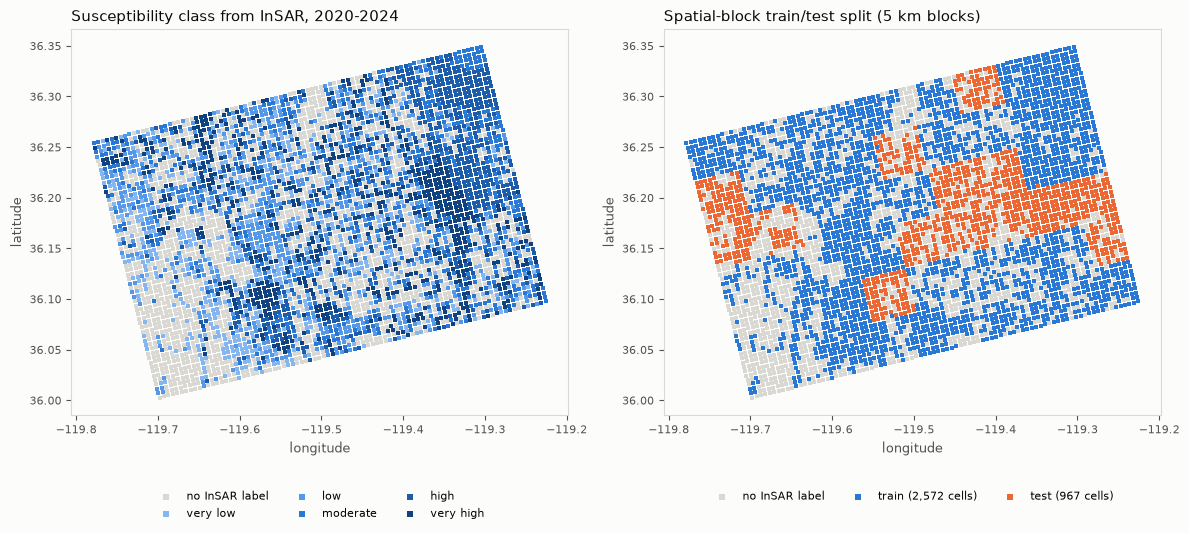

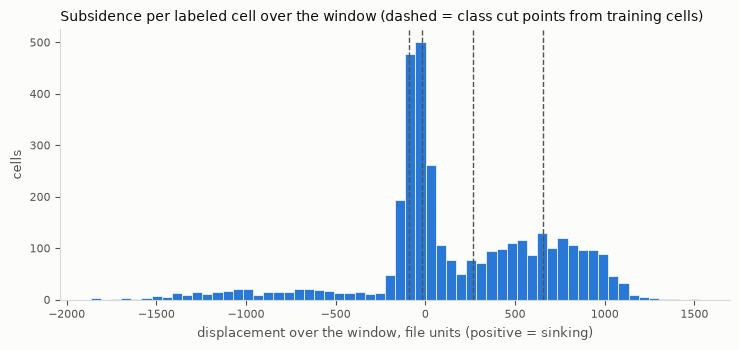

Saved figures/label_and_split_maps.png and figures/subsidence_distribution.png


In [28]:
if processed is None:
    print("Nothing to draw yet: Step 3 has not run.")
else:
    FIG_DIR.mkdir(exist_ok=True)
    INK, INK2, SURFACE, GRAY = "#0b0b0b", "#52514e", "#fcfcfb", "#d9d8d2"
    RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]   # five ordered classes, light -> dark
    TRAIN, TEST = "#2a78d6", "#eb6834"
    d = processed
    asp = 1 / np.cos(np.deg2rad(d.latitude.mean()))
    pretty = {"very_low": "very low", "low": "low", "moderate": "moderate", "high": "high", "very_high": "very high"}

    def style(ax, title):
        ax.set_facecolor(SURFACE)
        ax.set_aspect(asp)
        ax.set_title(title, loc="left", fontsize=11, color=INK)
        ax.set_xlabel("longitude", color=INK2, fontsize=9)
        ax.set_ylabel("latitude", color=INK2, fontsize=9)
        ax.tick_params(colors=INK2, labelsize=8)
        for s in ax.spines.values():
            s.set_color(GRAY)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), facecolor=SURFACE)
    ax = axes[0]
    un = d[d.susceptibility_class.isna()]
    ax.scatter(un.longitude, un.latitude, s=9, marker="s", color=GRAY, linewidths=0, label="no InSAR label")
    for lab, col in zip(LABELS, RAMP):
        sub = d[d.susceptibility_class == lab]
        ax.scatter(sub.longitude, sub.latitude, s=9, marker="s", color=col, linewidths=0, label=pretty[lab])
    style(ax, f"Susceptibility class from InSAR, {START[:4]}-{END[:4]}")
    ax.legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, markerscale=1.6)

    ax = axes[1]
    ax.scatter(un.longitude, un.latitude, s=9, marker="s", color=GRAY, linewidths=0, label="no InSAR label")
    for name, col in [("train", TRAIN), ("test", TEST)]:
        sub = d[(d.split == name) & d.subsidence.notna()]
        ax.scatter(sub.longitude, sub.latitude, s=9, marker="s", color=col, linewidths=0, label=f"{name} ({len(sub):,} cells)")
    style(ax, "Spatial-block train/test split (5 km blocks)")
    ax.legend(fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3, markerscale=1.6)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "label_and_split_maps.png", dpi=160, facecolor=SURFACE, bbox_inches="tight")
    plt.show()

    tr = d[(d.split == "train") & d.subsidence.notna()]
    cuts = tr.subsidence.quantile([.2, .4, .6, .8]).to_numpy()
    fig, ax = plt.subplots(figsize=(7.5, 3.6), facecolor=SURFACE)
    ax.set_facecolor(SURFACE)
    ax.hist(d.subsidence.dropna(), bins=60, color="#2a78d6", edgecolor=SURFACE, linewidth=0.5)
    for c in cuts:
        ax.axvline(c, color=INK2, lw=1, ls="--")
    ax.set_title("Subsidence per labeled cell over the window (dashed = class cut points from training cells)",
                 loc="left", fontsize=10, color=INK)
    ax.set_xlabel("displacement over the window, file units (positive = sinking)", color=INK2, fontsize=9)
    ax.set_ylabel("cells", color=INK2, fontsize=9)
    ax.tick_params(colors=INK2, labelsize=8)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        ax.spines[s].set_color(GRAY)
    fig.tight_layout()
    fig.savefig(FIG_DIR / "subsidence_distribution.png", dpi=160, facecolor=SURFACE)
    plt.show()
    print("Saved figures/label_and_split_maps.png and figures/subsidence_distribution.png")